In [11]:
import pandas as pd

In [12]:
df = pd.read_csv("ecommerce_sales_dataset.csv",parse_dates=['order_date'])

In [13]:
df.head()

,order_id,order_date,customer_id,customer_age,gender,customer_segment,region,city,category,sub_category,...,shipping_type,quantity,price,discount_pct,discount_amount,shipping_cost,total_amount,delivery_days,customer_rating,order_status
0,ORD103417,2024-02-05,CUST2808,57.0,Female,New,West,Surat,Beauty,Skincare,...,Express,2,585.15,50.0,585.15,100,585.15,3,3.6,Delivered
1,ORD103673,2024-12-28,CUST1809,51.0,Male,Regular,East,Kolkata,Electronics,Mobiles,...,Express,3,5829.63,15.0,2623.33,0,14865.56,6,5.0,Cancelled
2,ORD101137,2024-01-11,CUST2668,NaN,Male,Regular,Central,Indore,Home & Kitchen,Furniture,...,Express,3,1700.24,0.0,0.00,0,5100.72,1,2.9,Shipped
3,ORD102077,2024-07-20,CUST2539,44.0,Female,Regular,West,Surat,Home & Kitchen,Furniture,...,Express,1,3704.38,5.0,185.22,0,3519.16,6,2.1,Delivered
4,ORD101555,2025-07-29,CUST1497,59.0,Male,New,North,Delhi,Electronics,Mobiles,...,Standard,2,5897.83,0.0,0.00,0,11795.66,9,4.1,Delivered


In [14]:
df.shape

(5010, 22)

In [15]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_age', 'gender',
       'customer_segment', 'region', 'city', 'category', 'sub_category',
       'payment_method', 'device_type', 'shipping_type', 'quantity', 'price',
       'discount_pct', 'discount_amount', 'shipping_cost', 'total_amount',
       'delivery_days', 'customer_rating', 'order_status'],
      dtype='str')

In [16]:
df.dtypes

order_id                       str
order_date          datetime64[us]
customer_id                    str
customer_age               float64
gender                         str
customer_segment               str
region                         str
city                           str
category                       str
sub_category                   str
payment_method                 str
device_type                    str
shipping_type                  str
quantity                     int64
price                      float64
discount_pct               float64
discount_amount            float64
shipping_cost                int64
total_amount               float64
delivery_days                int64
customer_rating            float64
order_status                   str
dtype: object

In [17]:
df = df.drop_duplicates()

In [18]:
df.head()

,order_id,order_date,customer_id,customer_age,gender,customer_segment,region,city,category,sub_category,...,shipping_type,quantity,price,discount_pct,discount_amount,shipping_cost,total_amount,delivery_days,customer_rating,order_status
0,ORD103417,2024-02-05,CUST2808,57.0,Female,New,West,Surat,Beauty,Skincare,...,Express,2,585.15,50.0,585.15,100,585.15,3,3.6,Delivered
1,ORD103673,2024-12-28,CUST1809,51.0,Male,Regular,East,Kolkata,Electronics,Mobiles,...,Express,3,5829.63,15.0,2623.33,0,14865.56,6,5.0,Cancelled
2,ORD101137,2024-01-11,CUST2668,NaN,Male,Regular,Central,Indore,Home & Kitchen,Furniture,...,Express,3,1700.24,0.0,0.00,0,5100.72,1,2.9,Shipped
3,ORD102077,2024-07-20,CUST2539,44.0,Female,Regular,West,Surat,Home & Kitchen,Furniture,...,Express,1,3704.38,5.0,185.22,0,3519.16,6,2.1,Delivered
4,ORD101555,2025-07-29,CUST1497,59.0,Male,New,North,Delhi,Electronics,Mobiles,...,Standard,2,5897.83,0.0,0.00,0,11795.66,9,4.1,Delivered


In [19]:
df.shape

(5000, 22)

In [20]:
df.isnull().sum()

order_id              0
order_date            0
customer_id           0
customer_age        150
gender                0
customer_segment      0
region                0
city                  0
category              0
sub_category          0
payment_method        0
device_type           0
shipping_type        50
quantity              0
price                 0
discount_pct        100
discount_amount       0
shipping_cost         0
total_amount          0
delivery_days         0
customer_rating     250
order_status          0
dtype: int64

In [22]:
df['customer_age'] = df['customer_age'].fillna(df['customer_age'].median())
df['shipping_type'] = df['shipping_type'].fillna(df['shipping_type'].mode()[0])
df['discount_pct'] = df['discount_pct'].fillna(0)
df['customer_rating'] = df['customer_rating'].fillna(df['customer_rating'].mean())

In [24]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
customer_age        0
gender              0
customer_segment    0
region              0
city                0
category            0
sub_category        0
payment_method      0
device_type         0
shipping_type       0
quantity            0
price               0
discount_pct        0
discount_amount     0
shipping_cost       0
total_amount        0
delivery_days       0
customer_rating     0
order_status        0
dtype: int64

In [25]:
df['order_month'] = df['order_date'].dt.to_period("M").astype(str)
df['order_weekday'] = df['order_date'].dt.day_name()

In [26]:
df.shape

(5000, 24)

In [30]:
print(df.head())

    order_id order_date customer_id  customer_age  gender customer_segment  \
0  ORD103417 2024-02-05    CUST2808          57.0  Female              New   
1  ORD103673 2024-12-28    CUST1809          51.0    Male          Regular   
2  ORD101137 2024-01-11    CUST2668          41.0    Male          Regular   
3  ORD102077 2024-07-20    CUST2539          44.0  Female          Regular   
4  ORD101555 2025-07-29    CUST1497          59.0    Male              New   

    region     city        category sub_category  ...    price discount_pct  \
0     West    Surat          Beauty     Skincare  ...   585.15         50.0   
1     East  Kolkata     Electronics      Mobiles  ...  5829.63         15.0   
2  Central   Indore  Home & Kitchen    Furniture  ...  1700.24          0.0   
3     West    Surat  Home & Kitchen    Furniture  ...  3704.38          5.0   
4    North    Delhi     Electronics      Mobiles  ...  5897.83          0.0   

  discount_amount  shipping_cost  total_amount  delivery

# KPI

In [28]:
total_orders = len(df)

In [29]:
total_orders

5000

In [31]:
total_revenue = df.loc[df['order_status']=="Delivered","total_amount"].sum()

In [32]:
total_revenue

19750918.539608482

In [35]:
aov= df.loc[df['order_status']=="Delivered","total_amount"].mean()


In [36]:
aov

5020.569023794734

In [37]:
unique_customers = df['customer_id'].nunique()

print(unique_customers)

1835


In [38]:
df['customer_id'].value_counts()

customer_id
CUST2099    10
CUST1172     9
CUST1733     9
CUST2814     8
CUST2523     8
            ..
CUST2977     1
CUST1049     1
CUST1468     1
CUST1897     1
CUST2279     1
Name: count, Length: 1835, dtype: int64

In [41]:
repeat_customers = (df['customer_id'].value_counts() > 1).sum()

In [42]:
repeat_customers

1411

In [45]:
repeat_rate = repeat_customers/unique_customers * 100

In [47]:
repeat_rate

76.89373297002724

In [54]:
cancellation_rate = (df['order_status']=="Cancelled").mean() * 100

In [55]:
cancellation_rate

6.6000000000000005

In [56]:
df['order_status'].value_counts()

order_status
Delivered    3934
Shipped       491
Cancelled     330
Returned      245
Name: count, dtype: int64

In [57]:
returned_rate = (df['order_status']=="Returned").mean() * 100

In [58]:
returned_rate

4.9

In [59]:
avg_discount_pct = df['discount_pct'].mean()
avg_discount_pct

13.539

In [60]:
avg_rating = df['customer_rating'].mean()

In [61]:
avg_rating

4.003621052631579

In [62]:
avg_delivery_days = df['delivery_days'].mean()

In [63]:
avg_delivery_days

4.6982

In [65]:
top_category = df.groupby('category')['total_amount'].sum().idxmax()

top_category

'Electronics'

In [66]:
most_used_payment_method = df.groupby("payment_method")['total_amount'].sum().idxmax()
most_used_payment_method

'UPI'

# Insight

revenue by category

In [74]:
print(df.groupby('category')['total_amount'].sum().sort_values(ascending=False))

category
Electronics       1.591602e+07
Home & Kitchen    3.328494e+06
Fashion           2.304318e+06
Sports            1.547361e+06
Beauty            8.108854e+05
Toys              6.462443e+05
Books             3.155929e+05
Grocery           1.527849e+05
Name: total_amount, dtype: float64


order by category

In [75]:
df['category'].value_counts()

category
Electronics       1122
Fashion           1019
Home & Kitchen     697
Beauty             633
Sports             480
Books              409
Toys               384
Grocery            256
Name: count, dtype: int64

Average order value by category

In [76]:
print(df.groupby('category')['total_amount'].mean().sort_values(ascending=False))

category
Electronics       14185.401910
Home & Kitchen     4775.456966
Sports             3223.668479
Fashion            2261.352239
Toys               1682.927876
Beauty             1281.019573
Books               771.620793
Grocery             596.816172
Name: total_amount, dtype: float64


In [78]:
print(df.groupby('region')['total_amount'].sum().sort_values(ascending=False))

region
South      7.030395e+06
North      6.107927e+06
West       5.022090e+06
East       4.175813e+06
Central    2.685476e+06
Name: total_amount, dtype: float64


In [81]:
df['region'].value_counts(normalize=True)*100

region
South      26.64
North      23.86
West       21.02
East       18.44
Central    10.04
Name: proportion, dtype: float64

In [83]:
df['payment_method'].value_counts(normalize=True)*100

payment_method
UPI                 30.06
Credit Card         21.78
Cash on Delivery    17.66
Debit Card          15.20
Net Banking          8.30
Wallet               7.00
Name: proportion, dtype: float64

cancel and return rate for cash on delivery

In [86]:
df.loc[df["payment_method"]=="Cash on Delivery","order_status"].isin(['Cancelled',"Returned"]).mean()*100

12.231030577576444

over all cancel rate

In [90]:
df['order_status'].isin(["Cancelled","Returned"]).mean()*100

11.5

corelation between discount and total amount

In [91]:
df['discount_pct'].corr(df['total_amount'])

-0.08796144203472986

In [95]:
df["discount_pct"]

0       50.0
1       15.0
2        0.0
3        5.0
4        0.0
        ... 
5005     0.0
5006    15.0
5007     0.0
5008     0.0
5009    20.0
Name: discount_pct, Length: 5000, dtype: float64

In [93]:
df['discount_pct'].value_counts()

discount_pct
0.0     1303
5.0      766
10.0     696
15.0     553
20.0     528
25.0     410
30.0     343
40.0     254
50.0     147
Name: count, dtype: int64

Share contribution of orders discounted more than 30%

In [98]:
(df['discount_pct']>=30).mean()*100

14.879999999999999

In [99]:
df

,order_id,order_date,customer_id,customer_age,gender,customer_segment,region,city,category,sub_category,...,price,discount_pct,discount_amount,shipping_cost,total_amount,delivery_days,customer_rating,order_status,order_month,order_weekday
0,ORD103417,2024-02-05,CUST2808,57.0,Female,New,West,Surat,Beauty,Skincare,...,585.15,50.0,585.15,100,585.15,3,3.6,Delivered,2024-02,Monday
1,ORD103673,2024-12-28,CUST1809,51.0,Male,Regular,East,Kolkata,Electronics,Mobiles,...,5829.63,15.0,2623.33,0,14865.56,6,5.0,Cancelled,2024-12,Saturday
2,ORD101137,2024-01-11,CUST2668,41.0,Male,Regular,Central,Indore,Home & Kitchen,Furniture,...,1700.24,0.0,0.00,0,5100.72,1,2.9,Shipped,2024-01,Thursday
3,ORD102077,2024-07-20,CUST2539,44.0,Female,Regular,West,Surat,Home & Kitchen,Furniture,...,3704.38,5.0,185.22,0,3519.16,6,2.1,Delivered,2024-07,Saturday
4,ORD101555,2025-07-29,CUST1497,59.0,Male,New,North,Delhi,Electronics,Mobiles,...,5897.83,0.0,0.00,0,11795.66,9,4.1,Delivered,2025-07,Tuesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5005,ORD104307,2025-03-05,CUST2972,47.0,Male,Premium,West,Surat,Beauty,Fragrance,...,711.35,0.0,0.00,40,1422.70,7,3.8,Delivered,2025-03,Wednesday
5006,ORD102550,2025-11-11,CUST2304,26.0,Female,New,North,Jaipur,Fashion,Watches,...,447.26,15.0,67.09,40,380.17,5,5.0,Delivered,2025-11,Tuesday
5007,ORD100537,2024-09-01,CUST1902,50.0,Male,Regular,East,Bhubaneswar,Fashion,Bags,...,875.70,0.0,0.00,0,2627.10,4,4.3,Delivered,2024-09,Sunday
5008,ORD101220,2024-11-09,CUST1367,36.0,Male,Regular,South,Bengaluru,Grocery,Snacks,...,182.73,0.0,0.00,40,182.73,3,2.4,Delivered,2024-11,Saturday


In [101]:
df.groupby("customer_segment")['total_amount'].mean()

customer_segment
New        4894.383959
Premium    4720.260078
Regular    5112.987427
VIP        5574.901939
Name: total_amount, dtype: float64

In [102]:
df.groupby('shipping_type')['delivery_days'].mean()

shipping_type
Express     3.221649
Same-Day    1.340206
Standard    6.021262
Name: delivery_days, dtype: float64

In [103]:
df.groupby('shipping_type')['customer_rating'].mean()


shipping_type
Express     3.991447
Same-Day    4.000813
Standard    4.010457
Name: customer_rating, dtype: float64

In [106]:
df['order_status'].value_counts(normalize=True) * 100

order_status
Delivered    78.68
Shipped       9.82
Cancelled     6.60
Returned      4.90
Name: proportion, dtype: float64

In [107]:
df.groupby('gender')['total_amount'].mean()

gender
Female    4900.428947
Male      5101.192971
Other     5120.965446
Name: total_amount, dtype: float64

Revnue by age group

In [110]:
age_bins = pd.cut(df['customer_age'],
       bins=[17,25,35,45,55,65],
       labels=["18-25","26-35","36-45","46-55","56-65"])

In [113]:
age_rev = df.groupby(age_bins,observed=True)['total_amount'].sum().sort_values(ascending=False)

In [114]:
age_rev

customer_age
36-45    6.055840e+06
26-35    5.259655e+06
46-55    5.221788e+06
56-65    4.329037e+06
18-25    4.155382e+06
Name: total_amount, dtype: float64

In [130]:
month_rev = df.groupby("order_month")['total_amount'].mean()

In [119]:
weekday_order = ['Monday',"Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

In [120]:
df.groupby('order_weekday')['total_amount'].sum().reindex(weekday_order)

order_weekday
Monday       3.734248e+06
Tuesday      3.412950e+06
Wednesday    3.565292e+06
Thursday     3.648103e+06
Friday       3.739954e+06
Saturday     3.408858e+06
Sunday       3.512297e+06
Name: total_amount, dtype: float64

In [121]:
df.groupby('order_weekday')['total_amount'].mean().reindex(weekday_order)

order_weekday
Monday       4932.956449
Tuesday      4975.145982
Wednesday    5107.868421
Thursday     5102.241262
Friday       5088.372185
Saturday     4918.986710
Sunday       4905.442189
Name: total_amount, dtype: float64

In [122]:
df['quantity'].value_counts(normalize=True)*100

quantity
1    54.14
2    25.16
3    10.74
4     5.74
5     4.22
Name: proportion, dtype: float64

In [124]:
df.groupby('sub_category')['total_amount'].sum().idxmax()

'Laptops'

In [ ]:
pip install matplotlib

In [125]:
import matplotlib.pyplot as plt

In [126]:
cat_rev = df.groupby('category')['total_amount'].sum()

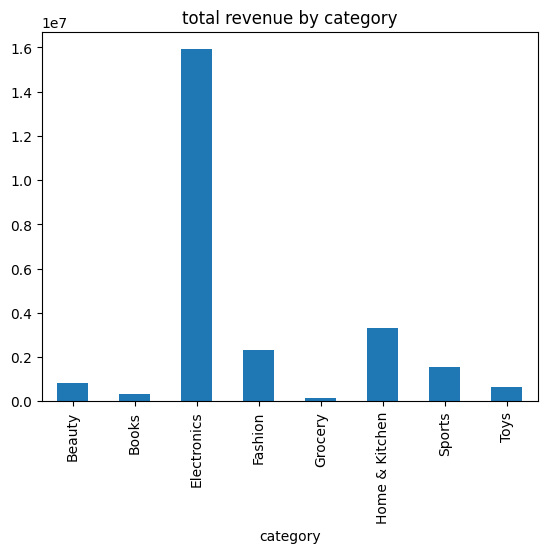

In [128]:
cat_rev.plot(kind='bar',title="total revenue by category")
plt.show()

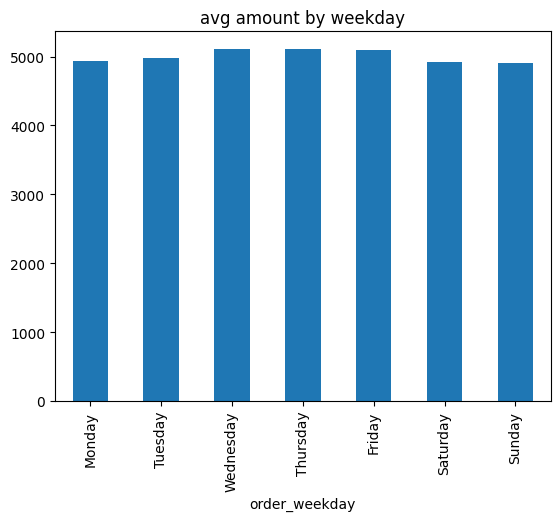

In [129]:
rev_wkdayt = df.groupby('order_weekday')['total_amount'].mean().reindex(weekday_order)


rev_wkdayt.plot(kind='bar')
plt.title("avg amount by weekday")
plt.show()

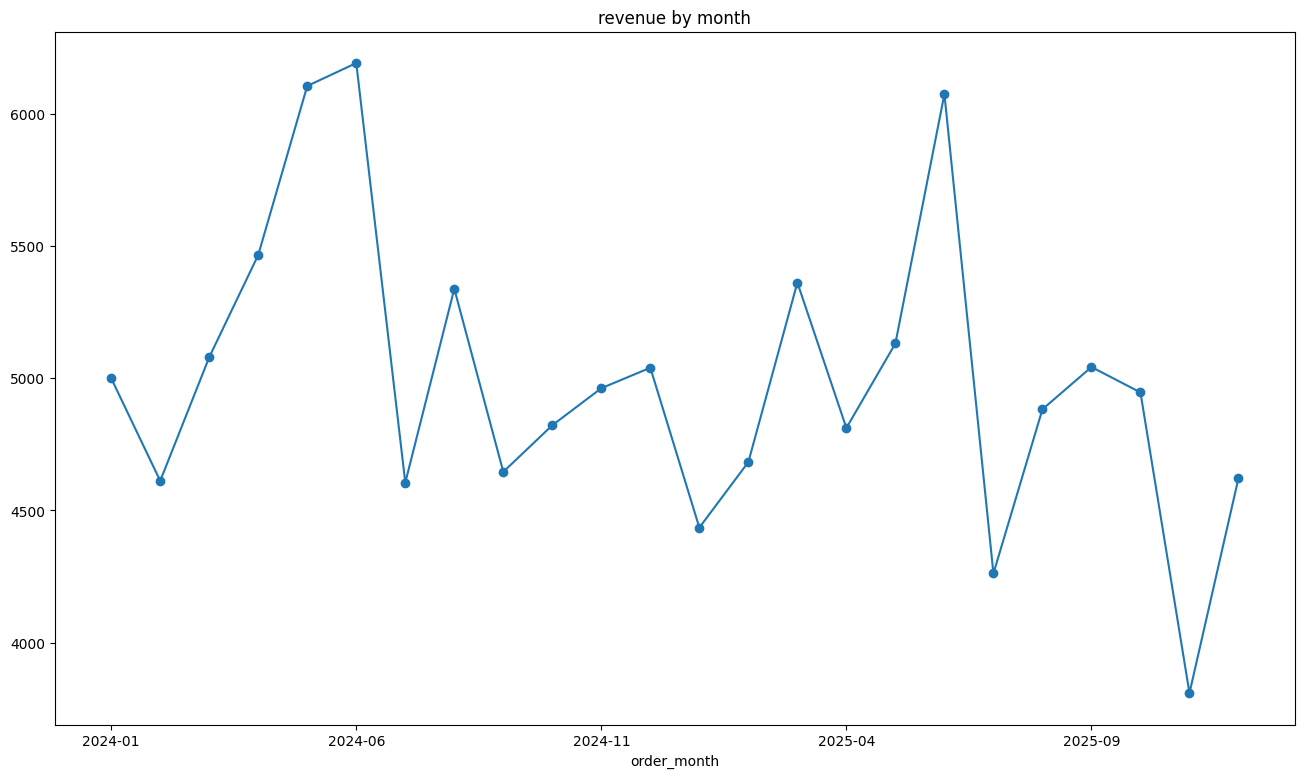

In [134]:
plt.figure(figsize=(16,9))
month_rev.plot(kind='line',marker='o')
plt.title("revenue by month")
plt.show()